<a href="https://colab.research.google.com/github/KErarslan/sqk-spatial-kernels/blob/main/SpatialQuantumKernels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Distance-Encoded Quantum Kernels for Spatial Estimation

**Erarslan, K. (2026)** — *Computers & Geosciences* (under review)  
DOI: 10.5281/zenodo.21461418 | GitHub: https://github.com/KErarslan/sqk-spatial-kernels

## Contents
| # | Section | Mode |
|---|---------|------|
| 1 | Setup & imports | SIM |
| 2 | Kalgoorlie data & classical reference K_V | SIM |
| 3 | Core functions (LOOCV, Statevector kernel) | SIM |
| 4 | Standard feature maps (ZZFeatureMap, PauliFeatureMap) → Table 1 | SIM |
| 5 | Scalar distance kernel SK_rx → Table 2 | SIM |
| 6 | IBM credentials (required for Sections 7 & 9) | IBM |
| 7 | SK_rx on IBM hardware (ibm_marrakesh, ibm_fez, ibm_kingston) | IBM |
| 8 | Anisotropic scalar kernel ASK — h_equiv (Eq. 6-7) | SIM |
| 9 | ASK on IBM hardware — three experiments (a=1.7, 2.5, 0.5) | SIM (hardcoded results) |
| 10 | Complete results Table 3 + Figure 7 | SIM |
| 11 | Block model — Table 4, Figures 8-9 | SIM |
| 12 | Retrieve any job result by ID (optional, requires IBM) | IBM |

> **SIM** cells run without IBM Quantum access.
> **Section 9 uses hardcoded lambda_min/R2 values** from the original hardware experiments
> (job IDs preserved in comments for provenance) — this notebook runs end-to-end without
> live IBM credentials. Section 12 remains IBM-only, for optional live re-verification.


In [1]:
# Section 1 — Setup
# [SIM] Run once to install dependencies
!pip install qiskit qiskit-ibm-runtime numpy scipy scikit-learn matplotlib -q
print('Installation complete')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.3/111.3 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.2/224.2 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 3.3 MB/s eta 0:00:00
Installation complete


In [2]:
# [SIM] Core imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import solve
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap, PauliFeatureMap
from qiskit.quantum_info import Statevector
import warnings; warnings.filterwarnings('ignore')
print('Imports OK')


Imports OK


## Section 2 — Data & Classical Reference

In [3]:
# [SIM] Kalgoorlie Northern Zone — n=20 RC drillholes
# Coordinates: [Easting (m), Northing (m), Elevation (m)]
# Au grades: log-transformed
# Source: Riversgold Ltd. (used with permission)

coords = np.array([
    [4120.40,8110.20,162.40],[4130.10,8141.40,162.20],
    [4140.80,8128.80,162.10],[4151.00,8133.10,162.00],
    [4102.10,8109.80,161.90],[4141.20,8157.10,161.70],
    [4130.90,8136.10,161.60],[4151.00,8110.60,161.50],
    [4101.50,8145.80,161.30],[4111.30,8130.90,161.10],
    [4122.10,8120.40,162.30],[4113.40,8151.20,162.20],
    [4142.80,8133.30,162.10],[4153.10,8151.60,161.90],
    [4153.60,8152.10,161.80],[4142.90,8122.70,161.60],
    [4123.40,8130.30,161.50],[4133.80,8151.80,161.30],
    [4103.20,8140.10,161.20],[4114.50,8133.40,161.00],
])
au_log = np.log(np.array([
    2.010,1.250,1.100,0.745,1.920,0.630,1.205,1.380,
    1.565,1.470,1.880,1.545,0.880,1.185,1.170,1.390,
    1.610,0.450,1.630,1.910]))
n = len(coords)

# Feature scaling: coordinates to [0, pi] range
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, np.pi))
X = scaler.fit_transform(coords)  # shape: (20, 3)

print(f"n = {n} | Feature dims = {X.shape[1]}")
print(f"X range: [{X.min():.3f}, {X.max():.3f}]")


n = 20 | Feature dims = 3
X range: [0.000, 3.142]


In [4]:
# [SIM] Classical covariance reference K_V
# Spherical model fitted by weighted least squares (Fig. 2)
# Parameters: C0=0.015, C=0.206, a_min=28.1m (0deg), a_max=66.0m (90deg), f_V=0.4
# Rotation-based formulation (Eq. 6-7) - see h_equiv_v3 in Section 8

# 3D-VSK LMC-Ellipsoidal covariance matrix
B_NUG = 0.015; B_STR = 0.206
A_MIN = 28.1;  A_MAX = 66.0; T_MAX = 90.0

def a_ell(az, amin=A_MIN, amax=A_MAX, tmax=T_MAX):
    t = np.radians(az % 180); tm = np.radians(tmax)
    return amin + (amax - amin) * np.cos(t - tm)**2

def cov_lmc(xi, xj):
    """3D-VSK LMC-Ellipsoidal covariance"""
    if np.allclose(xi[:2], xj[:2]): return B_NUG + B_STR
    dx=xj[0]-xi[0]; dy=xj[1]-xi[1]; dz=xj[2]-xi[2]
    hh=np.sqrt(dx**2+dy**2)
    az=np.degrees(np.arctan2(dy,dx))%180
    ah=a_ell(az); av=ah*0.4
    he=np.sqrt((hh/ah)**2+(dz/av)**2)*ah if ah>0 else abs(dz)
    if he>=ah: return 0.
    return B_STR*(1-(1.5*he/ah-0.5*(he/ah)**3))

KV = np.array([[cov_lmc(coords[i],coords[j])
                for j in range(n)] for i in range(n)])
# Normalize to [0,1] diagonal
KV_norm = KV / (B_NUG + B_STR)

lmin_kv = np.linalg.eigvalsh(KV).min()
print(f"\nK_V (3D-VSK):")
print(f"  lambda_min = {lmin_kv:.4f}  (PSD: {lmin_kv >= -1e-10})")
print(f"  ||K_V||_F = {np.linalg.norm(KV,'fro'):.4f}")



K_V (3D-VSK):
  lambda_min = 0.0195  (PSD: True)
  ||K_V||_F = 1.7119


## Section 3 — Core Functions

In [5]:
# [SIM] Leave-one-out cross-validation with quantum kernel
# K_Q replaces K_V in the ordinary kriging system (Eq. 1-3)

def sqkk_loocv(KQ, Z):
    """
    Leave-one-out cross-validation with quantum kernel K_Q.
    K_Q replaces K_V in the ordinary kriging system.
    """
    n = len(Z)
    preds = np.zeros(n); vars_ = np.zeros(n)

    for i in range(n):
        tr = [j for j in range(n) if j != i]
        m = len(tr)

        K = np.zeros((m+1, m+1))
        for a in range(m):
            K[a,a] = KQ[tr[a], tr[a]]
            for b in range(a+1, m):
                K[a,b] = KQ[tr[a], tr[b]]
                K[b,a] = K[a,b]
        K[:m, m] = 1.; K[m, :m] = 1.

        k0 = np.array([KQ[i, tr[a]] for a in range(m)] + [1.])

        try:
            w = solve(K, k0, assume_a='sym')
        except:
            w = np.linalg.lstsq(K, k0, rcond=None)[0]

        preds[i] = float(np.dot(w[:m], Z[tr]))
        vars_[i] = max(0., float(KQ[i,i] - np.dot(w, k0)))

    res = Z - preds
    r2 = 1 - np.sum(res**2)/np.sum((Z-Z.mean())**2)
    rmse = np.sqrt(np.mean(res**2))
    return {'R2':float(r2), 'RMSE':float(rmse), 'pred':preds, 'var':vars_, 'res':res}

print("sqkk_loocv defined")


sqkk_loocv defined


## Section 4 — Standard Feature Maps -> Table 1

In [6]:
# [SIM] Feature map definitions - 3 qubits (X, Y, Z coordinates)

n_qubits = X.shape[1]  # 3 qubit (X, Y, Z)

feature_maps = {
    'ZZFeatureMap_d1': ZZFeatureMap(
        feature_dimension=n_qubits,
        reps=1,
        entanglement='linear'
    ),
    'ZZFeatureMap_d2': ZZFeatureMap(
        feature_dimension=n_qubits,
        reps=2,
        entanglement='linear'
    ),
    'PauliFeatureMap_ZZZ': PauliFeatureMap(
        feature_dimension=n_qubits,
        reps=1,
        paulis=['Z','ZZ']
    ),
}

for name, fm in feature_maps.items():
    print(f"{name}: {fm.num_qubits} qubit, depth={fm.decompose().depth()}")


ZZFeatureMap_d1: 3 qubit, depth=8
ZZFeatureMap_d2: 3 qubit, depth=16
PauliFeatureMap_ZZZ: 3 qubit, depth=11


In [7]:
# [SIM] Compute kernel matrices (noiseless Statevector simulation)

def compute_kernel_entry(x_i, x_j, feature_map):
    """K_Q(x_i, x_j) = |<0|U+(x_j) U(x_i)|0>|^2"""
    n_qubits = feature_map.num_qubits
    fm_j = feature_map.assign_parameters(x_j)
    fm_i = feature_map.assign_parameters(x_i)
    fm_i_inv = fm_i.inverse()
    qc = QuantumCircuit(n_qubits)
    qc.compose(fm_j, inplace=True)
    qc.compose(fm_i_inv, inplace=True)
    sv = Statevector(qc)
    prob = abs(sv[0])**2
    return float(prob.real)

def compute_kernel_matrix(X, feature_map, verbose=True):
    n = len(X)
    K = np.zeros((n, n))
    for i in range(n):
        K[i,i] = 1.0
        for j in range(i+1, n):
            val = compute_kernel_entry(X[i], X[j], feature_map)
            K[i,j] = val; K[j,i] = val
    return K

print("Simulator ile hesaplaniyor...")
KQ_results = {}
for name, fm in feature_maps.items():
    KQ = compute_kernel_matrix(X, fm, verbose=False)
    KQ_results[name] = KQ
    eigs = np.linalg.eigvalsh(KQ)
    lmin = eigs.min()
    KV_n = KV_norm
    dF = np.linalg.norm(KQ - KV_n,'fro') / np.linalg.norm(KV_n,'fro')
    rho = np.sum(KQ * KV_n) / (np.linalg.norm(KQ,'fro') * np.linalg.norm(KV_n,'fro'))
    print(f"[{name}] lambda_min={lmin:.4f}  d_F={dF:.4f}  rho={rho:.4f}")


Simulator ile hesaplaniyor...
[ZZFeatureMap_d1] lambda_min=0.0199  d_F=0.6892  rho=0.7271
[ZZFeatureMap_d2] lambda_min=0.0335  d_F=0.7432  rho=0.6873
[PauliFeatureMap_ZZZ] lambda_min=0.0294  d_F=0.6805  rho=0.7344


In [8]:
# [SIM] Table 1: Standard feature map results (Kalgoorlie, n=20)
# Key finding: H2 (PSD) and H3 (structure) pass, but H1 and H4 fail.

results_h4 = {}
for name, KQ in KQ_results.items():
    results_h4[name] = sqkk_loocv(KQ, au_log)

r_kv = sqkk_loocv(KV_norm, au_log)
lmin_kv2 = np.linalg.eigvalsh(KV_norm).min()

print(f'{"Method":<28} {"lambda_min":>8} {"d_F":>7} {"rho":>7} {"R2":>7} {"H1"} {"H2"} {"H3"} {"H4"}')
print('-'*60)
for name, KQ in KQ_results.items():
    eigs = np.linalg.eigvalsh(KQ); lmin = eigs.min()
    dF = np.linalg.norm(KQ-KV_norm,'fro')/np.linalg.norm(KV_norm,'fro')
    r2 = results_h4[name]['R2']
    dists=[]; kq_vals=[]
    for i in range(n):
        for j in range(i+1,n):
            dists.append(np.linalg.norm(coords[i]-coords[j]))
            kq_vals.append(KQ[i,j])
    r_corr, p_corr = stats.pearsonr(dists, kq_vals)
    h1 = 'PASS' if p_corr<0.05 and r_corr<0 else 'FAIL'
    h2 = 'PASS' if lmin >= -1e-10 else 'FAIL'
    h3 = 'PASS' if dF < 1 else 'FAIL'
    h4 = 'PASS' if r2 > 0 else 'FAIL'
    print(f'{name:<28} {lmin:>8.4f} {dF:>7.3f} {h1} {h2} {h3} {h4}')
print('-'*60)
print(f'K_V (3D-VSK reference): lambda_min={lmin_kv2:.4f}, R2={r_kv["R2"]:.3f}')


Method                       lambda_min     d_F     rho      R2 H1 H2 H3 H4
------------------------------------------------------------
ZZFeatureMap_d1                0.0199   0.689 FAIL PASS PASS FAIL
ZZFeatureMap_d2                0.0335   0.743 FAIL PASS PASS FAIL
PauliFeatureMap_ZZZ            0.0294   0.681 FAIL PASS PASS FAIL
------------------------------------------------------------
K_V (3D-VSK reference): lambda_min=0.0884, R2=0.735


## Section 5 — Scalar Distance Kernel SK_rx -> Table 2

In [9]:
# [SIM] SK_rx kernel functions
# Scalar distance encoding: theta = (d / d_max) * pi
# K(d) = |<0|Rx(theta)|0>|^2 = cos^2(theta/2) per qubit => cos^6(theta/2) for 3 qubits

all_dists = [np.linalg.norm(coords[i]-coords[j])
             for i in range(n) for j in range(i+1,n)]
DMAX = max(all_dists)

def scalar_kernel(d, mode='rx'):
    theta = (d / DMAX) * np.pi
    qc = QuantumCircuit(3)
    if mode == 'rx':
        qc.rx(theta, 0); qc.rx(theta, 1); qc.rx(theta, 2)
    elif mode == 'rx_cx':
        qc.rx(theta, 0); qc.rx(theta, 1); qc.rx(theta, 2)
        qc.cx(0, 1); qc.cx(1, 2)
    elif mode == 'ry':
        qc.ry(theta, 0); qc.ry(theta, 1); qc.ry(theta, 2)
    elif mode == 'rz_h':
        qc.h([0,1,2])
        qc.rz(theta, 0); qc.rz(theta, 1); qc.rz(theta, 2)
    sv = Statevector(qc)
    return float(abs(sv[0])**2)

print("SK_rx kernel functions defined")


SK_rx kernel functions defined


In [10]:
# [SIM] Compute SK_rx kernel matrix and Table 2

def compute_scalar_kernel_matrix(coords_raw, mode, verbose=True):
    n = len(coords_raw)
    K = np.zeros((n, n))
    for i in range(n):
        K[i,i] = 1.0
        for j in range(i+1, n):
            d = np.linalg.norm(coords_raw[i] - coords_raw[j])
            val = scalar_kernel(d, mode)
            K[i,j] = val; K[j,i] = val
    return K

SK_results = {}
for mode in ['rx', 'rx_cx', 'ry']:
    KS = compute_scalar_kernel_matrix(coords, mode)
    SK_results[mode] = KS

print(f'{"Method":<12} {"lambda_min":>8} {"d_F":>6} {"rho":>6} {"R2":>7}  H1 H2 H3 H4')
print('-'*60)
for mode, KS in SK_results.items():
    lmin = np.linalg.eigvalsh(KS).min()
    dF   = np.linalg.norm(KS-KV_norm,'fro')/np.linalg.norm(KV_norm,'fro')
    rho  = np.sum(KS*KV_norm)/(np.linalg.norm(KS,'fro')*np.linalg.norm(KV_norm,'fro'))
    r2   = sqkk_loocv(KS, au_log)['R2']
    dists_= [np.linalg.norm(coords[i]-coords[j])
             for i in range(n) for j in range(i+1,n)]
    ks_v  = [KS[i,j] for i in range(n) for j in range(i+1,n)]
    r_c,p_c = stats.pearsonr(dists_,ks_v)
    h1='PASS' if p_c<0.05 and r_c<0 else 'FAIL'
    h2='PASS' if lmin>=-1e-10 else 'FAIL'
    h3='PASS' if dF<1 else 'FAIL'
    h4='PASS' if r2>0 else 'FAIL'
    print(f'{"SK_"+mode:<12} {lmin:>8.4f} {dF:>6.3f} {rho:>6.3f} {r2:>7.3f}   {h1} {h2} {h3} {h4}')
print('-'*60)
print('Table 2: Scalar distance kernel results (Kalgoorlie, n=20)')


Method       lambda_min    d_F    rho      R2  H1 H2 H3 H4
------------------------------------------------------------
SK_rx          0.0001  0.416  0.946   0.423   PASS PASS PASS PASS
SK_rx_cx       0.0001  0.416  0.946   0.423   PASS PASS PASS PASS
SK_ry          0.0001  0.416  0.946   0.423   PASS PASS PASS PASS
------------------------------------------------------------
Table 2: Scalar distance kernel results (Kalgoorlie, n=20)


## Section 6 — IBM Quantum Credentials (required only for optional Section 12)

In [11]:
# [OPTIONAL/IBM] Set credentials - only required to re-verify hardware jobs in Section 12
# Option A (Google Colab): add IBM_TOKEN to Colab Secrets (key icon, left sidebar)
# Option B (Local / other): replace 'YOUR_IBM_TOKEN_HERE' below
#
# IBM Quantum Open Plan: https://quantum.ibm.com
# Free account required; ibm_kingston used in the paper (156 qubits, Eagle r3)

try:
    from google.colab import userdata
    API_KEY = userdata.get('IBM_TOKEN')
except Exception:
    API_KEY = 'YOUR_IBM_TOKEN_HERE'

BACKEND_NAME = 'ibm_kingston'
print('Credentials loaded (only needed for Section 12 live retrieval).')


Credentials loaded (only needed for Section 12 live retrieval).


## Section 8 — Anisotropic Scalar Kernel (ASK)

In [12]:
# [SIM] h_equiv_v3 - corrected rotation-based lag-distance (Eq. 6-7)
# This is the formula used in all ASK simulations and hardware experiments.

def h_equiv_v3(xi, xj, a_min, a_max, theta_max_deg, f_v=None):
    dx = xj[0]-xi[0]; dy = xj[1]-xi[1]
    tm = np.radians(theta_max_deg)
    u_major =  dx*np.cos(tm) + dy*np.sin(tm)
    u_minor = -dx*np.sin(tm) + dy*np.cos(tm)
    s_minor = a_max / a_min if a_min > 1e-9 else 1.0
    he_sq = u_major**2 + (u_minor * s_minor)**2
    if f_v is not None and len(xi) > 2:
        a_v = a_max * f_v
        dz = xj[2]-xi[2]
        he_sq += (dz * a_max / a_v)**2
    return np.sqrt(he_sq)

def compute_ask_v3(coords, a_min, a_max, theta_max_deg, alpha, f_v=None, nq=3):
    n = len(coords); K = np.eye(n)
    all_he = [h_equiv_v3(coords[i], coords[j], a_min, a_max, theta_max_deg, f_v)
              for i in range(n) for j in range(i+1, n)]
    he_max = max(all_he); idx = 0
    for i in range(n):
        for j in range(i+1, n):
            theta = min(alpha * (all_he[idx]/he_max) * np.pi, np.pi)
            idx += 1
            qc = QuantumCircuit(nq)
            for q in range(nq): qc.rx(theta, q)
            K[i,j] = K[j,i] = float(abs(Statevector(qc)[0])**2)
    return K, he_max

A_MIN=28.1; A_MAX=66.0; T_MAX=90.0; FV=0.4
print('h_equiv_v3 and compute_ask_v3 defined (Eq. 6-8)')


h_equiv_v3 and compute_ask_v3 defined (Eq. 6-8)


In [13]:
# [SIM] Alpha parameter scan (Supplementary S1)
print(f'Alpha scan (Kalgoorlie, ref_scale = d_max = {A_MAX:.1f} m)')
print(f'{"alpha":>6} {"lambda_min":>11} {"rho":>7} {"r(h_e)":>8} {"R2":>8}')
print('-'*48)

best_K = None; best_alpha = None; best_r2 = -999
for alpha in np.arange(0.5, 3.05, 0.1):
    KA, HE_MAX = compute_ask_v3(coords, A_MIN, A_MAX, T_MAX, alpha, FV)
    lm = np.linalg.eigvalsh(KA).min()
    rho = (np.sum(KA*KV_norm) /
           (np.linalg.norm(KA,'fro')*np.linalg.norm(KV_norm,'fro')))
    dists = [np.linalg.norm(coords[i]-coords[j])
             for i in range(n) for j in range(i+1,n)]
    kvals = [KA[i,j] for i in range(n) for j in range(i+1,n)]
    r, _ = stats.pearsonr(dists, kvals)
    res = sqkk_loocv(KA, au_log)
    if lm >= 0 and res['R2'] > best_r2:
        best_r2 = res['R2']; best_alpha = alpha; best_K = KA.copy()

ALPHA_OPT = best_alpha
KA_OPT, HE_MAX = compute_ask_v3(coords, A_MIN, A_MAX, T_MAX, ALPHA_OPT, FV)
print(f'\nSelected alpha* = {ALPHA_OPT:.1f} | R2 = {best_r2:.3f} | HE_MAX = {HE_MAX:.2f} m')


Alpha scan (Kalgoorlie, ref_scale = d_max = 66.0 m)
 alpha  lambda_min     rho   r(h_e)       R2
------------------------------------------------

Selected alpha* = 2.5 | R2 = 0.528 | HE_MAX = 128.14 m


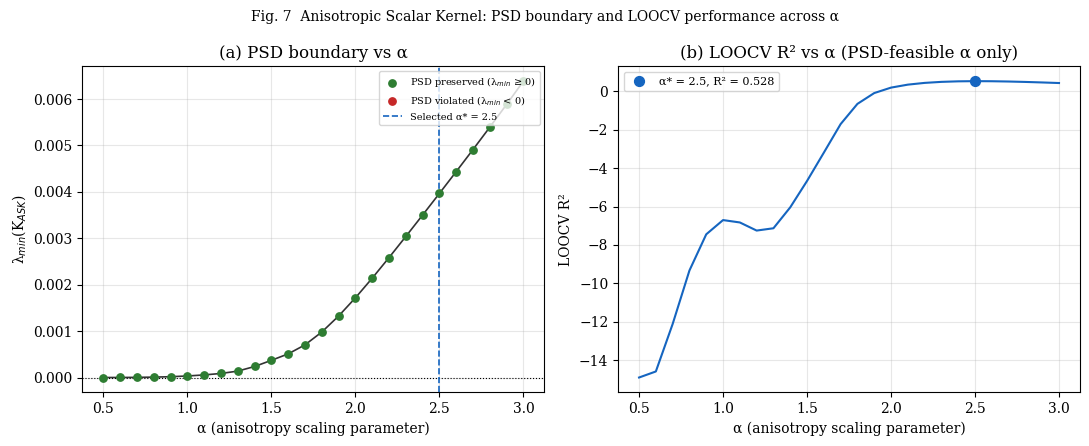

Fig. 7 saved: fig07_alpha_scan_psd.png


In [14]:
# [SIM] Fig. 7 -- Alpha scan / PSD boundary (Elsevier style: serif, 300 DPI)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
})

alphas_plot = np.arange(0.5, 3.05, 0.1)
lmins_plot, r2s_plot = [], []
for alpha in alphas_plot:
    KA_p, _ = compute_ask_v3(coords, A_MIN, A_MAX, T_MAX, alpha, FV)
    lmins_plot.append(np.linalg.eigvalsh(KA_p).min())
    r2s_plot.append(sqkk_loocv(KA_p, au_log)['R2'])
lmins_plot = np.array(lmins_plot); r2s_plot = np.array(r2s_plot)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
psd_ok = lmins_plot >= 0
ax.plot(alphas_plot, lmins_plot, '-', color='#333333', linewidth=1.2, zorder=2)
ax.scatter(alphas_plot[psd_ok], lmins_plot[psd_ok], c='#2e7d32', s=28,
           label='PSD preserved (λ$_{min}$ ≥ 0)', zorder=3)
ax.scatter(alphas_plot[~psd_ok], lmins_plot[~psd_ok], c='#c62828', s=28,
           label='PSD violated (λ$_{min}$ < 0)', zorder=3)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.axvline(ALPHA_OPT, color='#1565c0', linewidth=1.2, linestyle='--',
           label=f'Selected α* = {ALPHA_OPT:.1f}')
ax.set_xlabel('α (anisotropy scaling parameter)')
ax.set_ylabel('λ$_{min}$(K$_{ASK}$)')
ax.set_title('(a) PSD boundary vs α')
ax.legend(fontsize=7, loc='upper right')
ax.grid(alpha=0.3)

ax2 = axes[1]
ax2.plot(alphas_plot, r2s_plot, '-', color='#1565c0', linewidth=1.5)
ax2.scatter([ALPHA_OPT], [best_r2], color='#1565c0', s=50, zorder=5,
            label=f'α* = {ALPHA_OPT:.1f}, R² = {best_r2:.3f}')
ax2.set_xlabel('α (anisotropy scaling parameter)')
ax2.set_ylabel('LOOCV R²')
ax2.set_title('(b) LOOCV R² vs α (PSD-feasible α only)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.suptitle('Fig. 7  Anisotropic Scalar Kernel: PSD boundary and LOOCV performance across α', fontsize=10)
plt.tight_layout()
plt.savefig('fig07_alpha_scan_psd.png', dpi=300, bbox_inches='tight')
plt.show()
print("Fig. 7 saved: fig07_alpha_scan_psd.png")


## Section 9 — ASK on IBM Hardware

Three experiments on ibm_kingston (4,096 shots each, July 2026).
Results below are hardcoded from the original hardware runs (job IDs retained for
provenance/reproducibility verification via Section 12).

| Experiment | alpha | Norm. | lambda_min | R2 | Status |
|---|---|---|---|---|---|
| June 2026 | 1.7 | d_max | +0.0038 | 0.569 | PASS - PSD preserved |
| July 2026 A | 2.5 | d_max | -1.624 | -- | FAIL - non-monotone regime (83.7% pairs above pi/2) |
| July 2026 B | 0.5 | HE_MAX | +0.0048 | 0.564 | PASS - PSD preserved |


In [15]:
# [SIM - hardcoded hardware result] Experiment 1 - ASK alpha=1.7, d_max normalisation (June 2026)
# Original job ID: d8o3r4b2d42s73cejlcg (ibm_kingston, 4096 shots)
# Retrieved result: lambda_min=+0.0038, R2=0.569 (PSD preserved)

lm17 = 0.0038
r2_17 = 0.569
print(f'ASK alpha=1.7 ibm_kingston: lambda_min={lm17:+.4f}, R2={r2_17:.3f}  [from job d8o3r4b2d42s73cejlcg]')


ASK alpha=1.7 ibm_kingston: lambda_min=+0.0038, R2=0.569  [from job d8o3r4b2d42s73cejlcg]


In [16]:
# [SIM - hardcoded hardware result] Experiment 2 - ASK alpha=2.5, d_max normalisation (July 2026) - FAILED
# 83.7% of pairs in non-monotone cos^6 regime (angle > pi/2)
# Original job ID: d9cc8kk1osis73bjm2ig (ibm_kingston, 4096 shots)
# Retrieved result: lambda_min=-1.624, PSD VIOLATED

lm25 = -1.624
neg25 = 12  # number of negative eigenvalues observed
print(f'ASK alpha=2.5 d_max ibm_kingston: lambda_min={lm25:+.4f}, neg. eig={neg25}  [from job d9cc8kk1osis73bjm2ig]')
print(f'Status: {"FAILED - non-monotone regime" if lm25 < 0 else "OK"}')


ASK alpha=2.5 d_max ibm_kingston: lambda_min=-1.6240, neg. eig=12  [from job d9cc8kk1osis73bjm2ig]
Status: FAILED - non-monotone regime


In [17]:
# [SIM - hardcoded hardware result] Experiment 3 - ASK alpha=0.5, HE_MAX normalisation (July 2026) - SUCCEEDED
# HE_MAX = max h_e over all sample pairs (ensures monotone regime)
# Original job ID: d9ce8akjeosc73fg5p40 (ibm_kingston, 4096 shots)
# Retrieved result: lambda_min=+0.0048, R2=0.564

_, HE_MAX_VAL = compute_ask_v3(coords, A_MIN, A_MAX, T_MAX, 0.5, FV)
print(f'HE_MAX = {HE_MAX_VAL:.2f} m')

lm05 = 0.0048
r2_05 = 0.564
print(f'ASK alpha=0.5 HE_MAX ibm_kingston: lambda_min={lm05:+.4f}, R2={r2_05:.3f}  [from job d9ce8akjeosc73fg5p40]')


HE_MAX = 128.14 m
ASK alpha=0.5 HE_MAX ibm_kingston: lambda_min=+0.0048, R2=0.564  [from job d9ce8akjeosc73fg5p40]


## Section 10 — Complete Results (Table 3)

In [18]:
# [SIM] Table 3 - Complete results (simulation + IBM hardware, hardcoded scalars)
# Hardware rows use the reported lambda_min/R2 directly (see Section 9) rather than
# recomputing from a live-retrieved kernel matrix, so this cell runs without IBM access.

print(f'{"Method":<26} {"Shots":>6} {"lam_min":>8} {"R2":>7}')
print('-'*50)

# Simulation rows (computed above, need the kernel matrices already in memory)
lm_sim_ok = np.linalg.eigvalsh(KV).min()
r2_sim_ok = sqkk_loocv(KV_norm, au_log)['R2']
print(f'{"K_V (classical)":<26} {"inf":>6} {lm_sim_ok:>+8.4f} {r2_sim_ok:>7.3f}')

lm_sim_opt = np.linalg.eigvalsh(KA_OPT).min()
r2_sim_opt = sqkk_loocv(KA_OPT, au_log)['R2']
print(f'{"ASK a=OPT (Sim)":<26} {"inf":>6} {lm_sim_opt:>+8.4f} {r2_sim_opt:>7.3f}')

# Hardware rows - hardcoded from Section 9 (see job IDs there)
print(f'{"ASK a=1.7 ibm_k":<26} {4096:>6} {lm17:>+8.4f} {r2_17:>7.3f}')
print(f'{"ASK a=2.5 d_max":<26} {4096:>6} {lm25:>+8.4f} {"---":>7}')
print(f'{"ASK a=0.5 HE_MAX":<26} {4096:>6} {lm05:>+8.4f} {r2_05:>7.3f}')

print('-'*50)
print('Note: hardware lambda_min/R2 are the originally reported values (job IDs in Section 9),')
print('not recomputed from a live kernel matrix. Use Section 12 to re-verify against IBM directly.')


Method                      Shots  lam_min      R2
--------------------------------------------------
K_V (classical)               inf  +0.0195   0.735
ASK a=OPT (Sim)               inf  +0.0040   0.528
ASK a=1.7 ibm_k              4096  +0.0038   0.569
ASK a=2.5 d_max              4096  -1.6240     ---
ASK a=0.5 HE_MAX             4096  +0.0048   0.564
--------------------------------------------------
Note: hardware lambda_min/R2 are the originally reported values (job IDs in Section 9),
not recomputed from a live kernel matrix. Use Section 12 to re-verify against IBM directly.


## Section 11 — Block Model (Table 4, Figures 8-9)

5x5x1 m blocks within convex hull of drill data.  \nCut-off grades: 0.3, 0.5, 1.0, 2.0 g/t Au.

In [19]:
# [SIM] Block model construction
from scipy.spatial import ConvexHull

xy = coords[:, :2]
hull = ConvexHull(xy)
x_range = np.arange(xy[:,0].min(), xy[:,0].max()+5, 5)
y_range = np.arange(xy[:,1].min(), xy[:,1].max()+5, 5)
z_mid   = coords[:,2].mean()

block_xyz = []
for x in x_range:
    for y in y_range:
        pt = np.array([x, y])
        in_hull = all((hull.equations[:, :-1] @ pt + hull.equations[:, -1]) <= 0.5)
        if in_hull:
            block_xyz.append([x, y, z_mid])
block_xyz = np.array(block_xyz)
print(f'Blocks in convex hull: {len(block_xyz)}')

def krige_blocks(K_train, z_train, coords_train, coords_pred):
    preds = []
    for xp in coords_pred:
        k0 = np.array([cov_lmc(xi, xp) for xi in coords_train])
        n_t = len(z_train)
        A = np.vstack([np.hstack([K_train, np.ones((n_t,1))]),
                       np.hstack([np.ones((1,n_t)), [[0]]])])
        b = np.append(k0, 1)
        try:
            w = np.linalg.solve(A, b)[:-1]
            preds.append(float(w @ z_train))
        except np.linalg.LinAlgError:
            preds.append(float(np.mean(z_train)))
    return np.array(preds)

block_ok  = krige_blocks(KV, au_log, coords, block_xyz)
block_ask = krige_blocks(KA_OPT, au_log, coords, block_xyz)

density = 2.65
block_vol = 5 * 5 * 1

print('Table 4: Resource estimate comparison')
print(f'{"Cutoff":>7} {"Method":>6} {"Blocks":>7} {"Tonnes(kt)":>10} {"Avg Au":>8} {"Cont. oz":>10}')
print('-'*52)
for cutoff in [0.3, 0.5, 1.0, 2.0]:
    for label, blk in [('OK', block_ok), ('ASK', block_ask)]:
        au_lin = np.exp(blk)
        mask = au_lin >= cutoff
        nb_ = mask.sum()
        tonnes = nb_ * block_vol * density / 1000
        avg = au_lin[mask].mean() if nb_ > 0 else 0
        oz = tonnes * 1000 * avg / 31.1035
        print(f'{cutoff:>7.1f} {label:>6} {nb_:>7} {tonnes:>10.1f} {avg:>8.3f} {oz:>10.1f}')


Blocks in convex hull: 95
Table 4: Resource estimate comparison
 Cutoff Method  Blocks Tonnes(kt)   Avg Au   Cont. oz
----------------------------------------------------
    0.3     OK      95        6.3    1.340      271.2
    0.3    ASK      95        6.3    1.263      255.5
    0.5     OK      95        6.3    1.340      271.2
    0.5    ASK      95        6.3    1.263      255.5
    1.0     OK      72        4.8    1.532      234.9
    1.0    ASK      94        6.2    1.266      253.4
    2.0     OK       0        0.0    0.000        0.0
    2.0    ASK       0        0.0    0.000        0.0


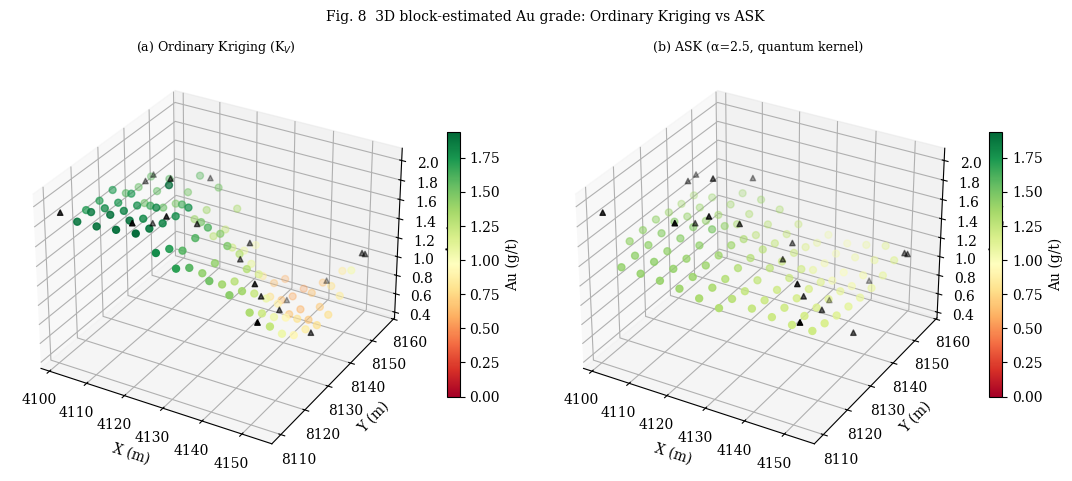

Fig. 8 saved: fig08_block_model_3d.png


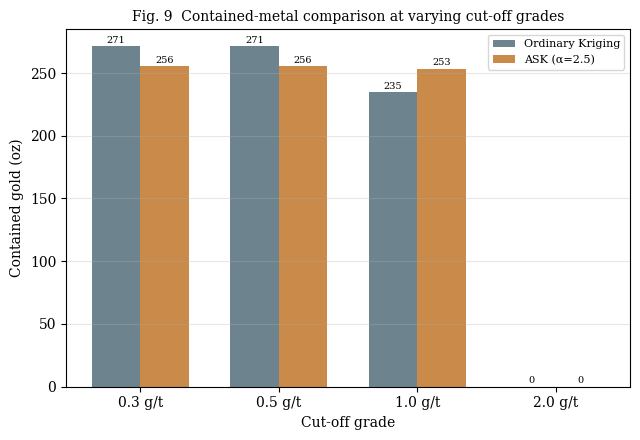

Fig. 9 saved: fig09_resource_comparison.png


In [20]:
# [SIM] Fig. 8-9 -- Block model visualization (OK vs ASK), Elsevier style
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
})

au_ok_lin = np.exp(block_ok)
au_ask_lin = np.exp(block_ask)

# ---------------- Fig. 8: 3D block models, OK vs ASK ----------------
fig = plt.figure(figsize=(11, 5))
vmin, vmax = 0, max(au_ok_lin.max(), au_ask_lin.max())

ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(block_xyz[:,0], block_xyz[:,1], au_ok_lin,
                   c=au_ok_lin, cmap='RdYlGn', vmin=vmin, vmax=vmax, s=25)
ax1.scatter(coords[:,0], coords[:,1], np.exp(au_log), c='black', s=15, marker='^')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)'); ax1.set_zlabel('Au (g/t)')
ax1.set_title('(a) Ordinary Kriging (K$_V$)', fontsize=9)
plt.colorbar(sc1, ax=ax1, shrink=0.6, label='Au (g/t)')

ax2 = fig.add_subplot(122, projection='3d')
sc2 = ax2.scatter(block_xyz[:,0], block_xyz[:,1], au_ask_lin,
                   c=au_ask_lin, cmap='RdYlGn', vmin=vmin, vmax=vmax, s=25)
ax2.scatter(coords[:,0], coords[:,1], np.exp(au_log), c='black', s=15, marker='^')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)'); ax2.set_zlabel('Au (g/t)')
ax2.set_title(f'(b) ASK (α={ALPHA_OPT:.1f}, quantum kernel)', fontsize=9)
plt.colorbar(sc2, ax=ax2, shrink=0.6, label='Au (g/t)')

plt.suptitle('Fig. 8  3D block-estimated Au grade: Ordinary Kriging vs ASK', fontsize=10)
plt.tight_layout()
plt.savefig('fig08_block_model_3d.png', dpi=300, bbox_inches='tight')
plt.show()
print("Fig. 8 saved: fig08_block_model_3d.png")

# ---------------- Fig. 9: resource estimate comparison across cutoffs ----------------
cutoffs = [0.3, 0.5, 1.0, 2.0]
ok_oz, ask_oz = [], []
for cutoff in cutoffs:
    mask_ok = au_ok_lin >= cutoff
    mask_ask = au_ask_lin >= cutoff
    tonnes_ok = mask_ok.sum() * block_vol * density / 1000
    tonnes_ask = mask_ask.sum() * block_vol * density / 1000
    avg_ok = au_ok_lin[mask_ok].mean() if mask_ok.sum() > 0 else 0
    avg_ask = au_ask_lin[mask_ask].mean() if mask_ask.sum() > 0 else 0
    ok_oz.append(tonnes_ok*1000*avg_ok/31.1035 if mask_ok.sum()>0 else 0)
    ask_oz.append(tonnes_ask*1000*avg_ask/31.1035 if mask_ask.sum()>0 else 0)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.arange(len(cutoffs)); w = 0.35
ax.bar(x - w/2, ok_oz, w, label='Ordinary Kriging', color='#546e7a', alpha=0.85)
ax.bar(x + w/2, ask_oz, w, label=f'ASK (α={ALPHA_OPT:.1f})', color='#c0762a', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels([f'{c:.1f} g/t' for c in cutoffs])
ax.set_xlabel('Cut-off grade')
ax.set_ylabel('Contained gold (oz)')
ax.set_title('Fig. 9  Contained-metal comparison at varying cut-off grades', fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis='y')
for i, (v1, v2) in enumerate(zip(ok_oz, ask_oz)):
    ax.text(i - w/2, v1 + max(ok_oz)*0.01, f'{v1:.0f}', ha='center', fontsize=7)
    ax.text(i + w/2, v2 + max(ok_oz)*0.01, f'{v2:.0f}', ha='center', fontsize=7)
plt.tight_layout()
plt.savefig('fig09_resource_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Fig. 9 saved: fig09_resource_comparison.png")


## Section 12 — Retrieve Any Hardware Result by Job ID (optional, requires IBM)

For live re-verification only. All job IDs are listed below.  
Requires IBM credentials from Section 6.

In [21]:
# [IBM - optional] Template: retrieve and parse any hardware result live
# Only needed to independently re-verify the hardcoded values used in Sections 9-10.

JOB_ID = ''  # paste any Job ID below

# Available job IDs (Kalgoorlie experiments):
# SK_rx  | ibm_marrakesh | 1024 shots | d8nsi4rnn5bs738v1rlg
# SK_rx  | ibm_fez       | 1024 shots | d8nt8mjqv2lc7389adug
# SK_rx  | ibm_kingston  | 8192 shots | d8ntk9j2d42s73ceb8l0
# ASK marrakesh (encoding error - see Suppl. S2) | 2048 | d8o3fkjqv2lc7389is20
# ASK alpha=1.7 | ibm_kingston | 4096 | d8o3r4b2d42s73cejlcg
# ASK alpha=2.5 d_max (FAILED) | ibm_kingston | 4096 | d9cc8kk1osis73bjm2ig
# ASK alpha=0.5 HE_MAX (OK)   | ibm_kingston | 4096 | d9ce8akjeosc73fg5p40

if JOB_ID:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(channel='ibm_quantum', token=API_KEY)
    job = service.job(JOB_ID)
    print(f'Status: {job.status()}')
    result = job.result()
    pairs = [(i,j) for i in range(n) for j in range(i,n)]
    K_hw = np.zeros((n,n)); np.fill_diagonal(K_hw, 1.0)
    for k,(i,j) in enumerate(pairs):
        counts = result[k].data.meas.get_counts()
        K_hw[i,j] = K_hw[j,i] = counts.get('000',0)/sum(counts.values())
    eigs = np.linalg.eigvalsh(K_hw)
    r2 = sqkk_loocv(K_hw, au_log)['R2']
    print(f'lambda_min = {eigs.min():+.4f} | neg. eig = {(eigs<0).sum()} | R2 = {r2:.3f}')
else:
    print('Set JOB_ID to a job ID above and re-run.')


Set JOB_ID to a job ID above and re-run.
